# Week 5 Tasks 3-5: abrupt 2xCO2 and 4xCO2, Gregory regression, climate sensitivity

**Answer.**
- **Task 3:** both runs level off quickly, reaching 90% of their final warming by year 4. Over the last 10 of 30 years the change in global tas is **+1.81 K (2xCO2)** and **+2.51 K (4xCO2)**, with no significant trend. But the TOA imbalance does **not** return to the control's: it stays **+4.9 W m-2 (2x)** and **+7.8 W m-2 (4x)** above it.
- **Task 4:** Gregory intercepts are **8.08 ± 0.21 W m-2 (2x)** and **10.58 ± 0.32 W m-2 (4x)**, against Week 4's fixed-SST ERF of 6.97 and 10.41. Slopes (feedback parameter lambda) are **-1.75 ± 0.12** and **-1.13 ± 0.13 W m-2 K-1**.
- **Task 5:** the two ECS estimates disagree. The equilibrium 2xCO2 warming is **1.81 K**, while -F2x/lambda is **4.6 ± 0.2 K** (4.0 K with Week 4's ERF).
- **Why they disagree:** the run is not in true equilibrium. In earth-slab, land surface temperature is relaxed to climatology with `tdland = 1 day`, so land is a heat sink. The land surface warms only 0.35 K while the air above it warms 1.7 K, and about 3.8 W m-2 (global mean; 13 W m-2 per m2 of land) leaves through the land relaxation at 2x. Extrapolating the plateau to dN = 0 along the Gregory line gives 4.6 K, the same as -F2x/lambda. So the Gregory estimate is the better ECS for this model, and the plateau warming is an artefact of the prescribed land.
- **Side note (10-day land):** rerunning the whole chain on NCAR Casper with `tdland = 10 days` moves the two estimates together (2.3 K equilibrium vs 4.0 K from Gregory), which supports the land-drain explanation. See the last section.

**How the runs were made** (laptop CPU, about 14 min per model year; scripts in `nrp/`):

1. `make_slab_co2.py`: copies of the slab boundary file (`forcing_pd_t31.nc`, same as the control's) with `co2` = 840 and 1680 ppmv.
2. `run_slab.py qflux --branch`: the Q-flux control's final state (2040-01-01, from the Task 2 handoff) with the new CO2, for 30 years. A plain restore would keep 420 ppmv, because the atmosphere's carry holds its forcing, so `--branch` replaces `co2_vmr`. The log confirms `CO2 420.0 -> 840.0` and `-> 1680.0 ppmv`. The clock restarts at 2000, so year 2000 is the first year after the jump.
3. `summarize_slab.py`: `results/w5-task3_co2x{2,4}_{annual,clim}.nc`.

Baseline for all changes: the control's 2020-2039 (`results/w5-task2_qcontrol_annual.nc`).

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

In [2]:
R = "../results/"
ctl = xr.open_dataset(R + "w5-task2_qcontrol_annual.nc").sel(year=slice(2020, 2039))   # baseline: control's last 20 years
runs = {m: xr.open_dataset(R + f"w5-task3_co2x{m[0]}_annual.nc") for m in ("2xCO2", "4xCO2")}
for d in runs.values():
    assert (d.lat == ctl.lat).all() and (d.lon == ctl.lon).all()
    assert d.sizes["year"] == 30

# Week 4 fixed-SST ERF (week4/task 6 and 7.ipynb), W m-2 with standard error
ERF_W4 = {"2xCO2": (6.969, 0.056), "4xCO2": (10.410, 0.050)}

ocean = ctl.ocean_mask == 1
land = ctl.ocean_mask == 0
w = np.cos(np.deg2rad(ctl.lat))
def gmean(da, mask=None):
    """Area-weighted (cos lat) mean over lat/lon, optionally over a mask."""
    if mask is not None:
        da = da.where(mask)
    return da.weighted(w).mean(("lat", "lon"))
f_ocean = float(gmean(ocean.astype(float)))
print(f"ocean fraction {f_ocean:.3f}, land fraction {1 - f_ocean:.3f}")

def series(d):
    """Global-mean annual series of d, as in the control file."""
    return xr.Dataset({"tas": gmean(d.tas), "toa": gmean(d.rtnt), "sst": gmean(d.sst, ocean),
                       "tland": gmean(d.ts, land), "up": gmean(d.hfds_up, ocean)})
base = series(ctl)
sd = base.std("year", ddof=1)
base = base.mean("year")
anom = {m: series(d) - base for m, d in runs.items()}
yr = np.arange(1, 31)   # years since the CO2 jump (the clock restarts at 2000 when a run branches)
print(f"control 2020-2039: tas {float(base.tas):.2f} K (SD {float(sd.tas):.3f}), TOA {float(base.toa):+.2f} W m-2 (SD {float(sd.toa):.3f})")

ocean fraction 0.711, land fraction 0.289
control 2020-2039: tas 288.28 K (SD 0.020), TOA +5.43 W m-2 (SD 0.120)


## Task 3: time series

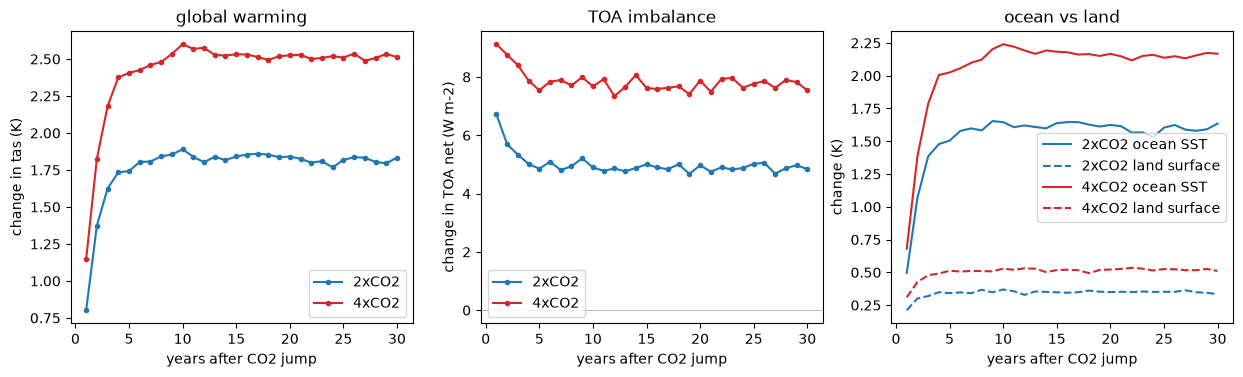

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for (m, a), c in zip(anom.items(), ("C0", "C3")):
    axs[0].plot(yr, a.tas, c + ".-", label=m)
    axs[1].plot(yr, a.toa, c + ".-", label=m)
    axs[2].plot(yr, a.sst, c + "-", label=m + " ocean SST")
    axs[2].plot(yr, a.tland, c + "--", label=m + " land surface")
axs[0].set_title("global warming")
axs[0].set_ylabel("change in tas (K)")
axs[1].set_title("TOA imbalance")
axs[1].set_ylabel("change in TOA net (W m-2)")
axs[1].axhline(0, c="0.6", lw=0.5)
axs[2].set_title("ocean vs land")
axs[2].set_ylabel("change (K)")
for ax in axs:
    ax.set_xlabel("years after CO2 jump")
    ax.legend()
plt.savefig("../figures/week5_co2_timeseries.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
def trend(s):
    """OLS trend of s in units per decade, with its standard error."""
    t = np.arange(len(s))
    p, cov = np.polyfit(t, s, 1, cov=True)
    return 10 * p[0], 10 * np.sqrt(cov[0, 0])

print(f"{'last 10 years':14s} {'tas K':>14s} {'TOA W m-2':>14s} {'ocean SST K':>12s} {'land K':>8s} {'tas trend K/dec':>18s}")
for m, a in anom.items():
    last = a.isel(year=slice(-10, None))
    tr, se = trend(last.tas.values)
    print(f"{m:14s} {float(last.tas.mean()):+7.2f} ± {float(last.tas.std(ddof=1)):.2f} {float(last.toa.mean()):+7.2f} ± {float(last.toa.std(ddof=1)):.2f}"
          f" {float(last.sst.mean()):+12.2f} {float(last.tland.mean()):+8.2f} {tr:+11.3f} ± {2 * se:.3f}")
    n90 = int(np.argmax(a.tas.values >= 0.9 * float(last.tas.mean()))) + 1
    print(f"{'':14s} reaches 90% of its final warming in year {n90}")

last 10 years           tas K      TOA W m-2  ocean SST K   land K    tas trend K/dec
2xCO2            +1.81 ± 0.02   +4.88 ± 0.12        +1.59    +0.35      +0.014 ± 0.049
               reaches 90% of its final warming in year 4
4xCO2            +2.51 ± 0.02   +7.75 ± 0.17        +2.15    +0.52      +0.001 ± 0.036
               reaches 90% of its final warming in year 4


**Task 3.** The global tas change stops rising after about 4 years, faster than the slab's 3-6 year e-folding time from Task 1, and its last-10-year trend is zero within error. The TOA imbalance falls in the first few years and then stays far above zero. A true equilibrium would bring the change in TOA net back to about 0. The right panel shows why: the ocean warms (1.6 K and 2.2 K), but the **land surface barely warms** (0.35 K and 0.52 K), because earth-slab relaxes land temperature to climatology with `tdland = 1 day`.

## Where the extra energy goes

In [5]:
RHO, CP = 1025.0, 3985.0   # jem.constants ocean density and heat capacity (as in nrp/make_qflux.py)
YEAR = 365.25 * 86400

def budget(d, a):
    """Global-mean W m-2: TOA change, heat entering the ocean surface, heat stored in the slab."""
    # hfds_up is F_up - Q (upward positive); Q is the same in both runs, so its change is the surface flux change
    into_ocean = -(d.hfds_up - ctl.hfds_up.mean("year")).where(ocean).fillna(0)
    sst = d.sst.where(ocean)
    dsst_dt = xr.DataArray(np.gradient(sst.values, axis=0), coords=sst.coords) / YEAR
    stored = (RHO * CP * d.mld * dsst_dt).where(ocean).fillna(0)
    return xr.Dataset({"dN": a.toa, "into ocean": gmean(into_ocean), "stored in slab": gmean(stored)})

print(f"{'last 10 years, global mean W m-2':34s} {'dN':>7s} {'into ocean':>11s} {'stored':>8s} {'not into ocean':>15s} {'per m2 of land':>15s}")
for m, d in runs.items():
    b = budget(d, anom[m]).isel(year=slice(-10, None)).mean("year")
    rest = float(b["dN"] - b["into ocean"])
    print(f"{m:34s} {float(b['dN']):+7.2f} {float(b['into ocean']):+11.2f} {float(b['stored in slab']):+8.2f}"
          f" {rest:+15.2f} {rest / (1 - f_ocean):+15.2f}")

last 10 years, global mean W m-2        dN  into ocean   stored  not into ocean  per m2 of land
2xCO2                                +4.88       +1.08    +0.02           +3.81          +13.17
4xCO2                                +7.75       +1.39    -0.00           +6.36          +22.03


**The energy goes into the land.** In the last 10 years the slab stores almost nothing (SST is steady), and only about 1.1-1.4 W m-2 (global mean) of the TOA change enters the ocean surface. That ocean part probably offsets a smaller freezing-clamp heat source as sea ice shrinks; we have not checked this. The rest, 3.8 W m-2 at 2x and 6.4 W m-2 at 4x, never enters the ocean. The atmosphere cannot store heat at equilibrium, so it has to leave through the land surface: 13 and 22 W m-2 per m2 of land. The map below shows that **air** over land warms almost as much as over the ocean (1.7 K against 1.9 K at 2x). So warm air sits over a land surface pinned near climatology, heat flows down into the land, and the relaxation removes it every day. With real (energy-conserving) land, this heat would warm the land surface until the TOA imbalance closed.

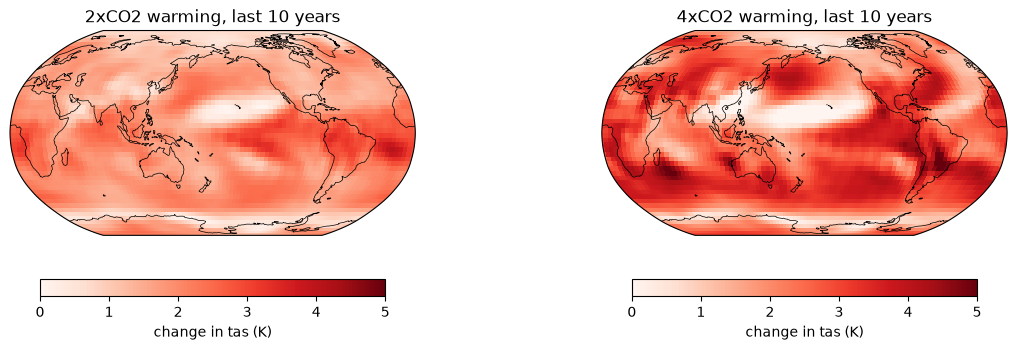

2xCO2: ocean-cell warming 1.85 K, land-cell warming 1.72 K
4xCO2: ocean-cell warming 2.49 K, land-cell warming 2.57 K


In [6]:
fig = plt.figure(figsize=(14, 3.8))
for i, (m, d) in enumerate(runs.items()):
    dT = (d.tas.isel(year=slice(-10, None)).mean("year") - ctl.tas.mean("year"))
    ax = fig.add_subplot(1, 2, i + 1, projection=ccrs.Robinson(central_longitude=180))
    p = dT.plot(ax=ax, transform=ccrs.PlateCarree(), cmap="Reds", vmin=0, vmax=5, add_colorbar=False)
    ax.coastlines(lw=0.5)
    ax.set_title(f"{m} warming, last 10 years")
    plt.colorbar(p, ax=ax, orientation="horizontal", shrink=0.7, label="change in tas (K)")
plt.savefig("../figures/week5_co2_warming_map.png", dpi=150, bbox_inches="tight")
plt.show()
for m, d in runs.items():
    dT = d.tas.isel(year=slice(-10, None)).mean("year") - ctl.tas.mean("year")
    print(f"{m}: ocean-cell warming {float(gmean(dT, ocean)):.2f} K, land-cell warming {float(gmean(dT, land)):.2f} K")

## Task 4: Gregory regression

In [7]:
def ols(x, y):
    """Fit y = a + b x. Returns (a, b) and their covariance matrix."""
    X = np.column_stack([np.ones_like(x), x])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    res = y - X @ beta
    cov = res @ res / (len(y) - 2) * np.linalg.inv(X.T @ X)
    return beta, cov

fits = {}
for m, a in anom.items():
    x, y = a.tas.values, a.toa.values
    fits[m] = ols(x, y)
    (ia, b), cov = fits[m]
    se = np.sqrt(np.diag(cov))
    (ia5, b5), _ = ols(x[:5], y[:5])
    (ia10, b10), _ = ols(x[:10], y[:10])
    erf, erf_se = ERF_W4[m]
    print(f"{m}: intercept {ia:.2f} ± {se[0]:.2f} W m-2 (Week 4 fixed-SST ERF {erf:.2f} ± {erf_se:.2f}),"
          f" slope {b:.2f} ± {se[1]:.2f} W m-2 K-1")
    print(f"       years 1-5 only: intercept {ia5:.2f}, slope {b5:.2f};  years 1-10: intercept {ia10:.2f}, slope {b10:.2f}")

2xCO2: intercept 8.08 ± 0.21 W m-2 (Week 4 fixed-SST ERF 6.97 ± 0.06), slope -1.75 ± 0.12 W m-2 K-1
       years 1-5 only: intercept 8.23, slope -1.86;  years 1-10: intercept 8.02, slope -1.68
4xCO2: intercept 10.58 ± 0.32 W m-2 (Week 4 fixed-SST ERF 10.41 ± 0.05), slope -1.13 ± 0.13 W m-2 K-1
       years 1-5 only: intercept 10.57, slope -1.12;  years 1-10: intercept 10.50, slope -1.08


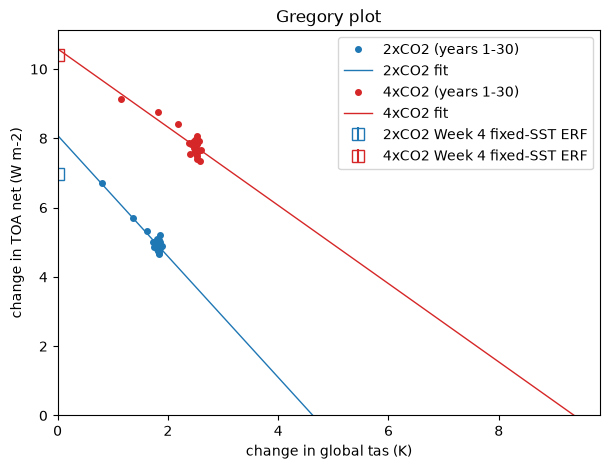

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
for (m, a), c in zip(anom.items(), ("C0", "C3")):
    (ia, b), _ = fits[m]
    ax.plot(a.tas, a.toa, c + "o", ms=4, label=f"{m} (years 1-30)")
    xs = np.linspace(0, -ia / b, 50)
    ax.plot(xs, ia + b * xs, c + "-", lw=1, label=f"{m} fit")
    ax.errorbar(0, ERF_W4[m][0], yerr=2 * ERF_W4[m][1], fmt=c + "s", mfc="none", ms=8, label=f"{m} Week 4 fixed-SST ERF")
ax.axhline(0, c="0.6", lw=0.5)
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.set_xlabel("change in global tas (K)")
ax.set_ylabel("change in TOA net (W m-2)")
ax.set_title("Gregory plot")
ax.legend()
plt.savefig("../figures/week5_co2_gregory.png", dpi=150, bbox_inches="tight")
plt.show()

**Task 4.**
- **Forcing.** At 4x the Gregory intercept (10.58 ± 0.32) matches the Week 4 fixed-SST ERF (10.41 ± 0.05). At 2x it is 1.1 W m-2 higher (8.08 ± 0.21 against 6.97 ± 0.06), well outside both errors. One difference is that Week 4's fixed-SST land could adjust, while here land is pinned from the first day. The Week 4 control in Linus's notebook (+4.88 W m-2) also differs slightly from the team control (+4.95). We have not tested either.
- **Feedback.** lambda = -1.75 W m-2 K-1 at 2x and -1.13 at 4x: the feedback is weaker at higher CO2, and fits to years 1-5 and 1-10 give nearly the same values, so the weakening is a difference between the runs, not a change within a run. The land sink is the likely cause. The intercept comes from the first 2-3 years, but the late points sit far above the zero line, because the land keeps draining heat.
- **Caveat.** Because the runs plateau in about 4 years, most of the 30 points cluster at the end, and the intercept and slope are set by the first 3-4 years. The standard errors assume independent residuals, so they are probably too small.

## Task 5: climate sensitivity

In [9]:
def ratio(F, b, var_F, var_b, cov_Fb=0.0):
    """-F / b and its standard error (first-order error propagation)."""
    e = -F / b
    var = var_F / b**2 + F**2 * var_b / b**4 - 2 * F * cov_Fb / b**3
    return e, np.sqrt(var)

(ia2, b2), c2 = fits["2xCO2"]
(ia4, b4), c4 = fits["4xCO2"]
last2 = anom["2xCO2"].isel(year=slice(-10, None))
dT_eq, dN_eq = float(last2.tas.mean()), float(last2.toa.mean())

est = {
    "1. equilibrium tas change, 2xCO2 run (last 10 years)": (dT_eq, float(last2.tas.std(ddof=1)) / np.sqrt(10)),
    "2. -F2x/lambda, Gregory 2xCO2 (own intercept)": ratio(ia2, b2, c2[0, 0], c2[1, 1], c2[0, 1]),
    "   -F2x/lambda, 2xCO2 slope with Week 4 ERF": ratio(ERF_W4["2xCO2"][0], b2, ERF_W4["2xCO2"][1] ** 2, c2[1, 1]),
    "   -(F4x/2)/lambda, Gregory 4xCO2": ratio(ia4 / 2, b4, c4[0, 0] / 4, c4[1, 1], c4[0, 1] / 2),
    "   last 10 years extrapolated to dN = 0 (2xCO2)": (dT_eq - dN_eq / b2, np.nan),
}
for k, (e, s) in est.items():
    print(f"{k:55s} {e:5.2f} K" + (f" ± {s:.2f}" if np.isfinite(s) else ""))
print(f"\n4xCO2 / 2xCO2 equilibrium warming: {float(anom['4xCO2'].tas[-10:].mean()) / dT_eq:.2f}"
      f"  (Week 4 ERF ratio {ERF_W4['4xCO2'][0] / ERF_W4['2xCO2'][0]:.2f}; log forcing would give 2)")
print("NorESM2-LM ECS 2.54 K (Seland et al. 2020); IPCC AR6: best 3 K, likely 2.5-4 K, very likely 2-5 K")

1. equilibrium tas change, 2xCO2 run (last 10 years)     1.81 K ± 0.01
2. -F2x/lambda, Gregory 2xCO2 (own intercept)            4.63 K ± 0.20
   -F2x/lambda, 2xCO2 slope with Week 4 ERF              3.99 K ± 0.28
   -(F4x/2)/lambda, Gregory 4xCO2                        4.68 K ± 0.40
   last 10 years extrapolated to dN = 0 (2xCO2)          4.61 K

4xCO2 / 2xCO2 equilibrium warming: 1.39  (Week 4 ERF ratio 1.49; log forcing would give 2)
NorESM2-LM ECS 2.54 K (Seland et al. 2020); IPCC AR6: best 3 K, likely 2.5-4 K, very likely 2-5 K


**Task 5.**

| ECS estimate | K |
|---|---|
| equilibrium 2xCO2 warming (last 10 years) | 1.81 |
| -F2x/lambda, 2xCO2 Gregory | 4.63 ± 0.20 |
| -F2x/lambda, Week 4 ERF and 2xCO2 slope | 3.99 ± 0.28 |
| -(F4x/2)/lambda, 4xCO2 Gregory | 4.68 ± 0.40 |
| NorESM2-LM (Seland et al. 2020) | 2.54 |
| IPCC AR6 | best 3, likely 2.5-4, very likely 2-5 |

- **The two methods disagree by a factor of 2.5.** The equilibrium warming (1.8 K) is below AR6's very likely range, and the Gregory value (4.6 K) is at its upper end and far above NorESM2-LM.
- **The Gregory value is the better ECS for this model.** The 2xCO2 run levels off with dN still +4.9 W m-2. Extrapolating along the Gregory slope to dN = 0 gives 1.81 + 4.88 / 1.75 = **4.6 K**, the same as -F2x/lambda. The plateau is an equilibrium only because the land relaxation removes the heat that would otherwise warm the planet further.
- **The 4xCO2 run gives the same -F/lambda (4.7 K)** with a weaker forcing and a weaker feedback, which cancel. Its warming is only 1.39 times the 2xCO2 warming, against a forcing ratio of 1.49 in Week 4 (log forcing would give 2).
- **For the brief's question 1:** no, the equilibrium ECS does not match -F2x/lambda. Here that is not mainly because lambda changes over a run (fits to the first 5 and 10 years give about the same slope), but because land with `tdland = 1 day` is an energy sink. A fair comparison needs energy-conserving land. The side note at the end reruns everything with a 10-day land relaxation: the gap shrinks from 1.8 vs 4.6 K to 2.3 vs 4.0 K, but does not close, since 10-day land still drains heat and longer settings blow up.

## Side note: land relaxation of 10 days instead of 1

To check that the land drain explains the gap between the two ECS estimates, we reran the whole chain (relaxed run, Q-flux, 40-year control, 2xCO2 and 4xCO2) with `tdland = 10 days`, using `run_slab.py --tdland 10` on NCAR Casper (V100 GPU). SPEEDY's default is 40 days, but 20 and 40 days blew up (non-finite SST) within the first year, so 10 days is the longest value that runs. At 10 days the drain is about 3 W m-2 per K of land warming, against about 29 at 1 day. The land still loses energy, but much less.

In [10]:
def on_ctl_grid(d):
    """Casper's GPU computes latitudes ~1e-13 off the Mac's; without this, xarray drops the unmatched ones."""
    assert np.allclose(d.lat, ctl.lat) and np.allclose(d.lon, ctl.lon)
    return d.assign_coords(lat=ctl.lat, lon=ctl.lon)

ctl10 = on_ctl_grid(xr.open_dataset(R + "w5-tdland10_qcontrol_annual.nc")).sel(year=slice(2020, 2039))
runs10 = {m: on_ctl_grid(xr.open_dataset(R + f"w5-tdland10_co2x{m[0]}_annual.nc")) for m in ("2xCO2", "4xCO2")}
assert float(ctl10.attrs["tdland_days"]) == 10.0
base10 = series(ctl10).mean("year")
anom10 = {m: series(d) - base10 for m, d in runs10.items()}
print(f"10-day control 2020-2039: tas {float(base10.tas):.2f} K, TOA {float(base10.toa):+.2f} W m-2")

print(f"{'':16s} {'dT K':>6s} {'dN':>6s} {'land ts K':>10s} {'F W m-2':>13s} {'lambda':>13s} {'-F2x/lambda K':>14s}")
for tag, an in (("1 d", anom), ("10 d", anom10)):
    for m, a in an.items():
        (ia, b), cov = ols(a.tas.values, a.toa.values)
        k = 1 if m == "2xCO2" else 2   # the 4xCO2 forcing is halved for F2x
        e, e_se = ratio(ia / k, b, cov[0, 0] / k**2, cov[1, 1], cov[0, 1] / k)
        se = np.sqrt(np.diag(cov))
        last = a.isel(year=slice(-10, None)).mean("year")
        print(f"{tag:5s} {m:10s} {float(last.tas):+6.2f} {float(last.toa):+6.2f} {float(last.tland):+10.2f}"
              f" {ia:6.2f} ± {se[0]:.2f} {b:6.2f} ± {se[1]:.2f} {e:8.2f} ± {e_se:.2f}")

10-day control 2020-2039: tas 288.64 K, TOA +5.00 W m-2
                   dT K     dN  land ts K       F W m-2        lambda  -F2x/lambda K
1 d   2xCO2       +1.81  +4.88      +0.35   8.08 ± 0.21  -1.75 ± 0.12     4.63 ± 0.20
1 d   4xCO2       +2.51  +7.75      +0.52  10.58 ± 0.32  -1.13 ± 0.13     4.68 ± 0.40
10 d  2xCO2       +2.31  +3.36      +1.84   8.14 ± 0.21  -2.05 ± 0.09     3.97 ± 0.08
10 d  4xCO2       +3.88  +5.40      +3.13  10.53 ± 0.31  -1.29 ± 0.08     4.07 ± 0.15


**Side note results.**

| last 10 of 30 years | tdland 1 d | tdland 10 d |
|---|---|---|
| 2xCO2 dT (equilibrium ECS) | 1.81 K | 2.31 K |
| 2xCO2 dN | +4.88 | +3.36 W m-2 |
| 2xCO2 land surface warming | +0.35 K | +1.84 K |
| 4xCO2 dT | 2.51 K | 3.88 K |
| 2xCO2 Gregory intercept | 8.08 ± 0.21 | 8.14 ± 0.21 W m-2 |
| 2xCO2 Gregory slope | -1.75 ± 0.12 | -2.05 ± 0.09 W m-2 K-1 |
| -F2x/lambda, 2xCO2 | 4.63 ± 0.20 K | 3.97 ± 0.08 K |
| -(F4x/2)/lambda, 4xCO2 | 4.68 ± 0.40 K | 4.07 ± 0.15 K |

- **The two ECS estimates move toward each other** (1.8 vs 4.6 K at 1 day, 2.3 vs 4.0 K at 10 days), so the land drain is the main reason they disagree. They still do not meet, because 10 days still drains land and the runs still level off with dN = +3.4 W m-2.
- **The forcing hardly changes** (8.08 vs 8.14 W m-2 at 2x), so the land setting changes the response, not the forcing. The 2x Gregory intercept is still about 1.2 W m-2 above Week 4's fixed-SST ERF.
- **Land now warms.** Land surface warming at 2x goes from +0.35 K to +1.84 K, and 4x warming is 1.68 times 2x warming (1.39 at 1 day).
- **The 10-day control has a large TOA imbalance too** (+5.0 W m-2 against +5.4 at 1 day) while its temperature is steady, so the land still removes energy in the control. The anomalies above are relative to that control, so this offset cancels, but neither setting gives an energy-conserving model.
- **Caveat:** 10-day land runs hot and cold (land ts from 207 to 324 K in a one-year test), which is the jax-esm#1 problem that the 1-day setting was chosen to hide. Treat this as a sensitivity test, not a better answer. Our main Task 3-5 results stay at earth-slab's 1-day setting.